# EDA — Pascal VOC 2012 Semantic Segmentation

[Dataset (Kaggle)](https://www.kaggle.com/datasets/gopalbhattrai/pascal-voc-2012-dataset) · EDA, metrics, visualizations

## 1. Data loading

Data already at: /Users/zakharstaryk/Downloads/scientificProject2/data/VOCdevkit/VOC2012
Train images: 1464
Val images:   1449
Total:        2913


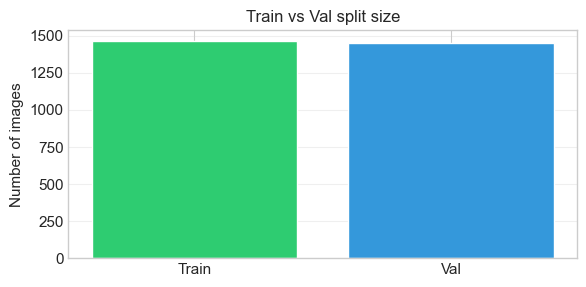

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from collections import Counter
import torchvision

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11})
sns.set_palette("husl")

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data" / "VOCdevkit" / "VOC2012"

if not DATA_DIR.exists():
    print("Downloading Pascal VOC 2012...")
    torchvision.datasets.VOCSegmentation(root=str(BASE_DIR / "data"), year="2012", download=True)
    print("Done.")
else:
    print(f"Data already at: {DATA_DIR}")

train_ids = (DATA_DIR / "ImageSets" / "Segmentation" / "train.txt").read_text().strip().split("\n")
val_ids = (DATA_DIR / "ImageSets" / "Segmentation" / "val.txt").read_text().strip().split("\n")

print(f"Train images: {len(train_ids)}")
print(f"Val images:   {len(val_ids)}")
print(f"Total:        {len(train_ids) + len(val_ids)}")

VOC_CLASSES = [
    "background", "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow", "diningtable", "dog",
    "horse", "motorbike", "person", "pottedplant", "sheep", "sofa",
    "train", "tvmonitor",
]
NUM_CLASSES = len(VOC_CLASSES)

VOC_COLORMAP = np.array([
    [0,0,0],[128,0,0],[0,128,0],[128,128,0],[0,0,128],[128,0,128],
    [0,128,128],[128,128,128],[64,0,0],[192,0,0],[64,128,0],[192,128,0],
    [64,0,128],[192,0,128],[64,128,128],[192,128,128],[0,64,0],[128,64,0],
    [0,192,0],[128,192,0],[0,64,128],
], dtype=np.uint8)

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Train", "Val"], [len(train_ids), len(val_ids)], color=["#2ecc71", "#3498db"])
ax.set_ylabel("Number of images")
ax.set_title("Train vs Val split size")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 2. EDA

### 2.1 Data integrity and structure

In [2]:
img_dir = DATA_DIR / "JPEGImages"
mask_dir = DATA_DIR / "SegmentationClass"

all_ids = train_ids + val_ids
missing_img, missing_mask = [], []
widths, heights = [], []
splits = []

for img_id in all_ids:
    ip = img_dir / f"{img_id}.jpg"
    mp = mask_dir / f"{img_id}.png"
    if not ip.exists():
        missing_img.append(img_id)
    if not mp.exists():
        missing_mask.append(img_id)
    if ip.exists():
        im = Image.open(ip)
        widths.append(im.width)
        heights.append(im.height)
        splits.append("train" if img_id in set(train_ids) else "val")

print(f"Missing images: {len(missing_img)}")
print(f"Missing masks:  {len(missing_mask)}")
print(f"\nImage sizes — width:  min={min(widths)}, max={max(widths)}, mean={np.mean(widths):.0f}")
print(f"Image sizes — height: min={min(heights)}, max={max(heights)}, mean={np.mean(heights):.0f}")

Missing images: 0
Missing masks:  0

Image sizes — width:  min=174, max=500, mean=472
Image sizes — height: min=112, max=500, mean=385


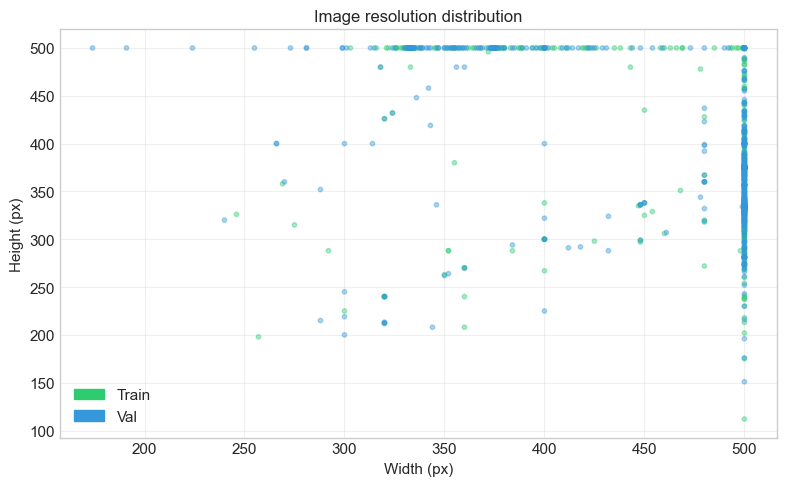

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#2ecc71" if s == "train" else "#3498db" for s in splits]
ax.scatter(widths, heights, c=colors, alpha=0.4, s=10)
ax.set_xlabel("Width (px)")
ax.set_ylabel("Height (px)")
ax.set_title("Image resolution distribution")
ax.legend(handles=[
    mpatches.Patch(color="#2ecc71", label="Train"),
    mpatches.Patch(color="#3498db", label="Val"),
])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.2 Class distribution (pixel-level)

In [4]:
pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
void_pixels = 0
images_per_class = np.zeros(NUM_CLASSES, dtype=np.int64)
objects_per_image = []

for img_id in train_ids:
    mask = np.array(Image.open(mask_dir / f"{img_id}.png"))
    void_pixels += np.sum(mask == 255)
    present_classes = set()
    for c in range(NUM_CLASSES):
        count = np.sum(mask == c)
        pixel_counts[c] += count
        if count > 0:
            present_classes.add(c)
            images_per_class[c] += 1
    objects_per_image.append(len(present_classes - {0}))

total_pixels = pixel_counts.sum() + void_pixels
print(f"Total pixels (train): {total_pixels:,}")
print(f"Void/border pixels:   {void_pixels:,} ({void_pixels/total_pixels*100:.2f}%)")

class_df = pd.DataFrame({
    "class": VOC_CLASSES,
    "pixel_count": pixel_counts,
    "pixel_%": (pixel_counts / pixel_counts.sum() * 100).round(2),
    "images_with_class": images_per_class,
    "image_%": (images_per_class / len(train_ids) * 100).round(1),
})
display(class_df)

Total pixels (train): 262,462,800
Void/border pixels:   14,335,564 (5.46%)


,class,pixel_count,pixel_%,images_with_class,image_%
0,background,182014429,73.36,1460,99.7
1,aeroplane,1780580,0.72,88,6.0
2,bicycle,758311,0.31,65,4.4
3,bird,2232247,0.90,105,7.2
4,boat,1514260,0.61,78,5.3
5,bottle,1517186,0.61,87,5.9
6,bus,4375622,1.76,78,5.3
7,car,3494749,1.41,128,8.7
8,cat,6752515,2.72,131,8.9
9,chair,2861091,1.15,148,10.1


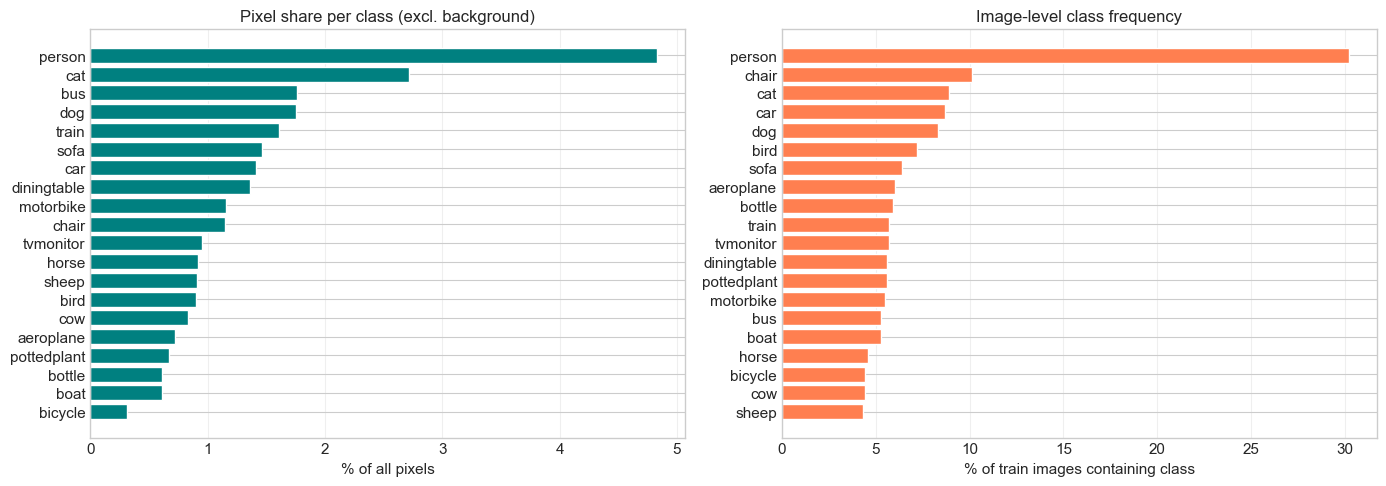

In [5]:
fg_df = class_df[class_df["class"] != "background"].sort_values("pixel_count", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(fg_df["class"], fg_df["pixel_%"], color="teal", edgecolor="white")
axes[0].set_xlabel("% of all pixels")
axes[0].set_title("Pixel share per class (excl. background)")
axes[0].grid(True, axis="x", alpha=0.3)

fg_df_img = class_df[class_df["class"] != "background"].sort_values("images_with_class", ascending=True)
axes[1].barh(fg_df_img["class"], fg_df_img["image_%"], color="coral", edgecolor="white")
axes[1].set_xlabel("% of train images containing class")
axes[1].set_title("Image-level class frequency")
axes[1].grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

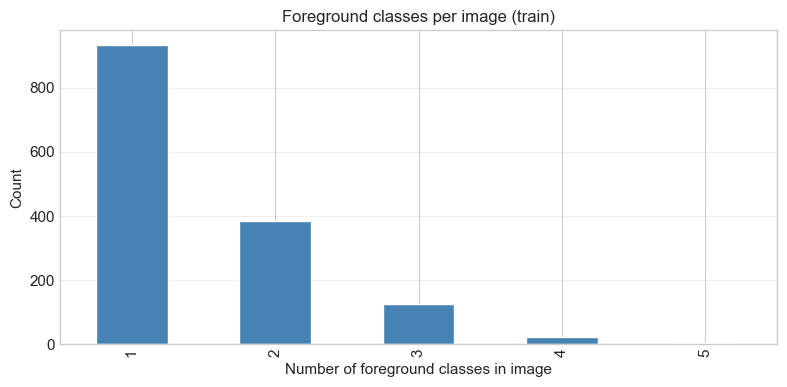

Mean classes/image: 1.48, Max: 5


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
pd.Series(objects_per_image).value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_xlabel("Number of foreground classes in image")
ax.set_ylabel("Count")
ax.set_title("Foreground classes per image (train)")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Mean classes/image: {np.mean(objects_per_image):.2f}, Max: {max(objects_per_image)}")

### 2.3 Class co-occurrence

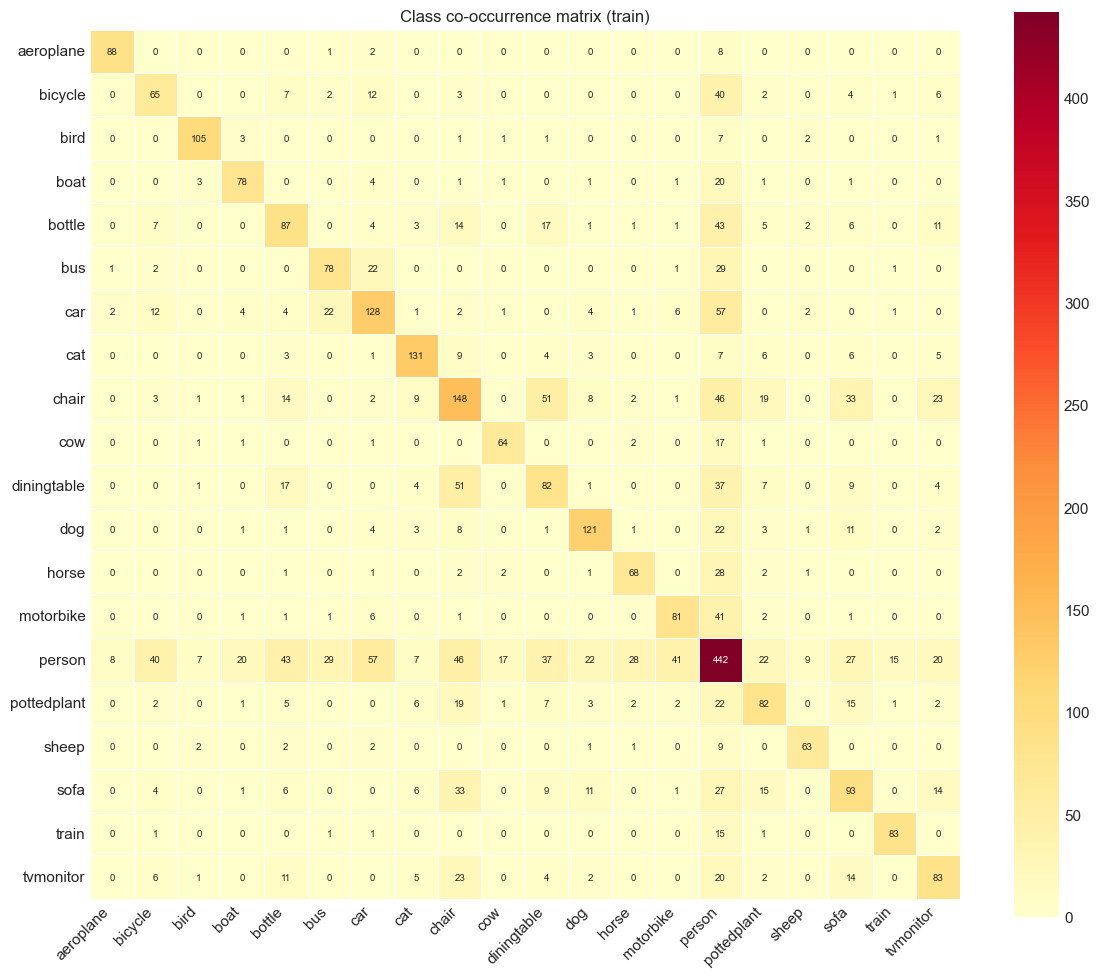

In [7]:
fg_classes = list(range(1, NUM_CLASSES))
cooccurrence = np.zeros((len(fg_classes), len(fg_classes)), dtype=np.int64)

for img_id in train_ids:
    mask = np.array(Image.open(mask_dir / f"{img_id}.png"))
    present = set(np.unique(mask)) - {0, 255}
    for ci in present:
        for cj in present:
            if 1 <= ci <= 20 and 1 <= cj <= 20:
                cooccurrence[ci - 1, cj - 1] += 1

fg_names = VOC_CLASSES[1:]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cooccurrence, xticklabels=fg_names, yticklabels=fg_names,
            cmap="YlOrRd", ax=ax, square=True, linewidths=0.5, fmt="d", annot=True, annot_kws={"size": 7})
ax.set_title("Class co-occurrence matrix (train)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 2.4 Sample visualizations (image + mask + overlay)

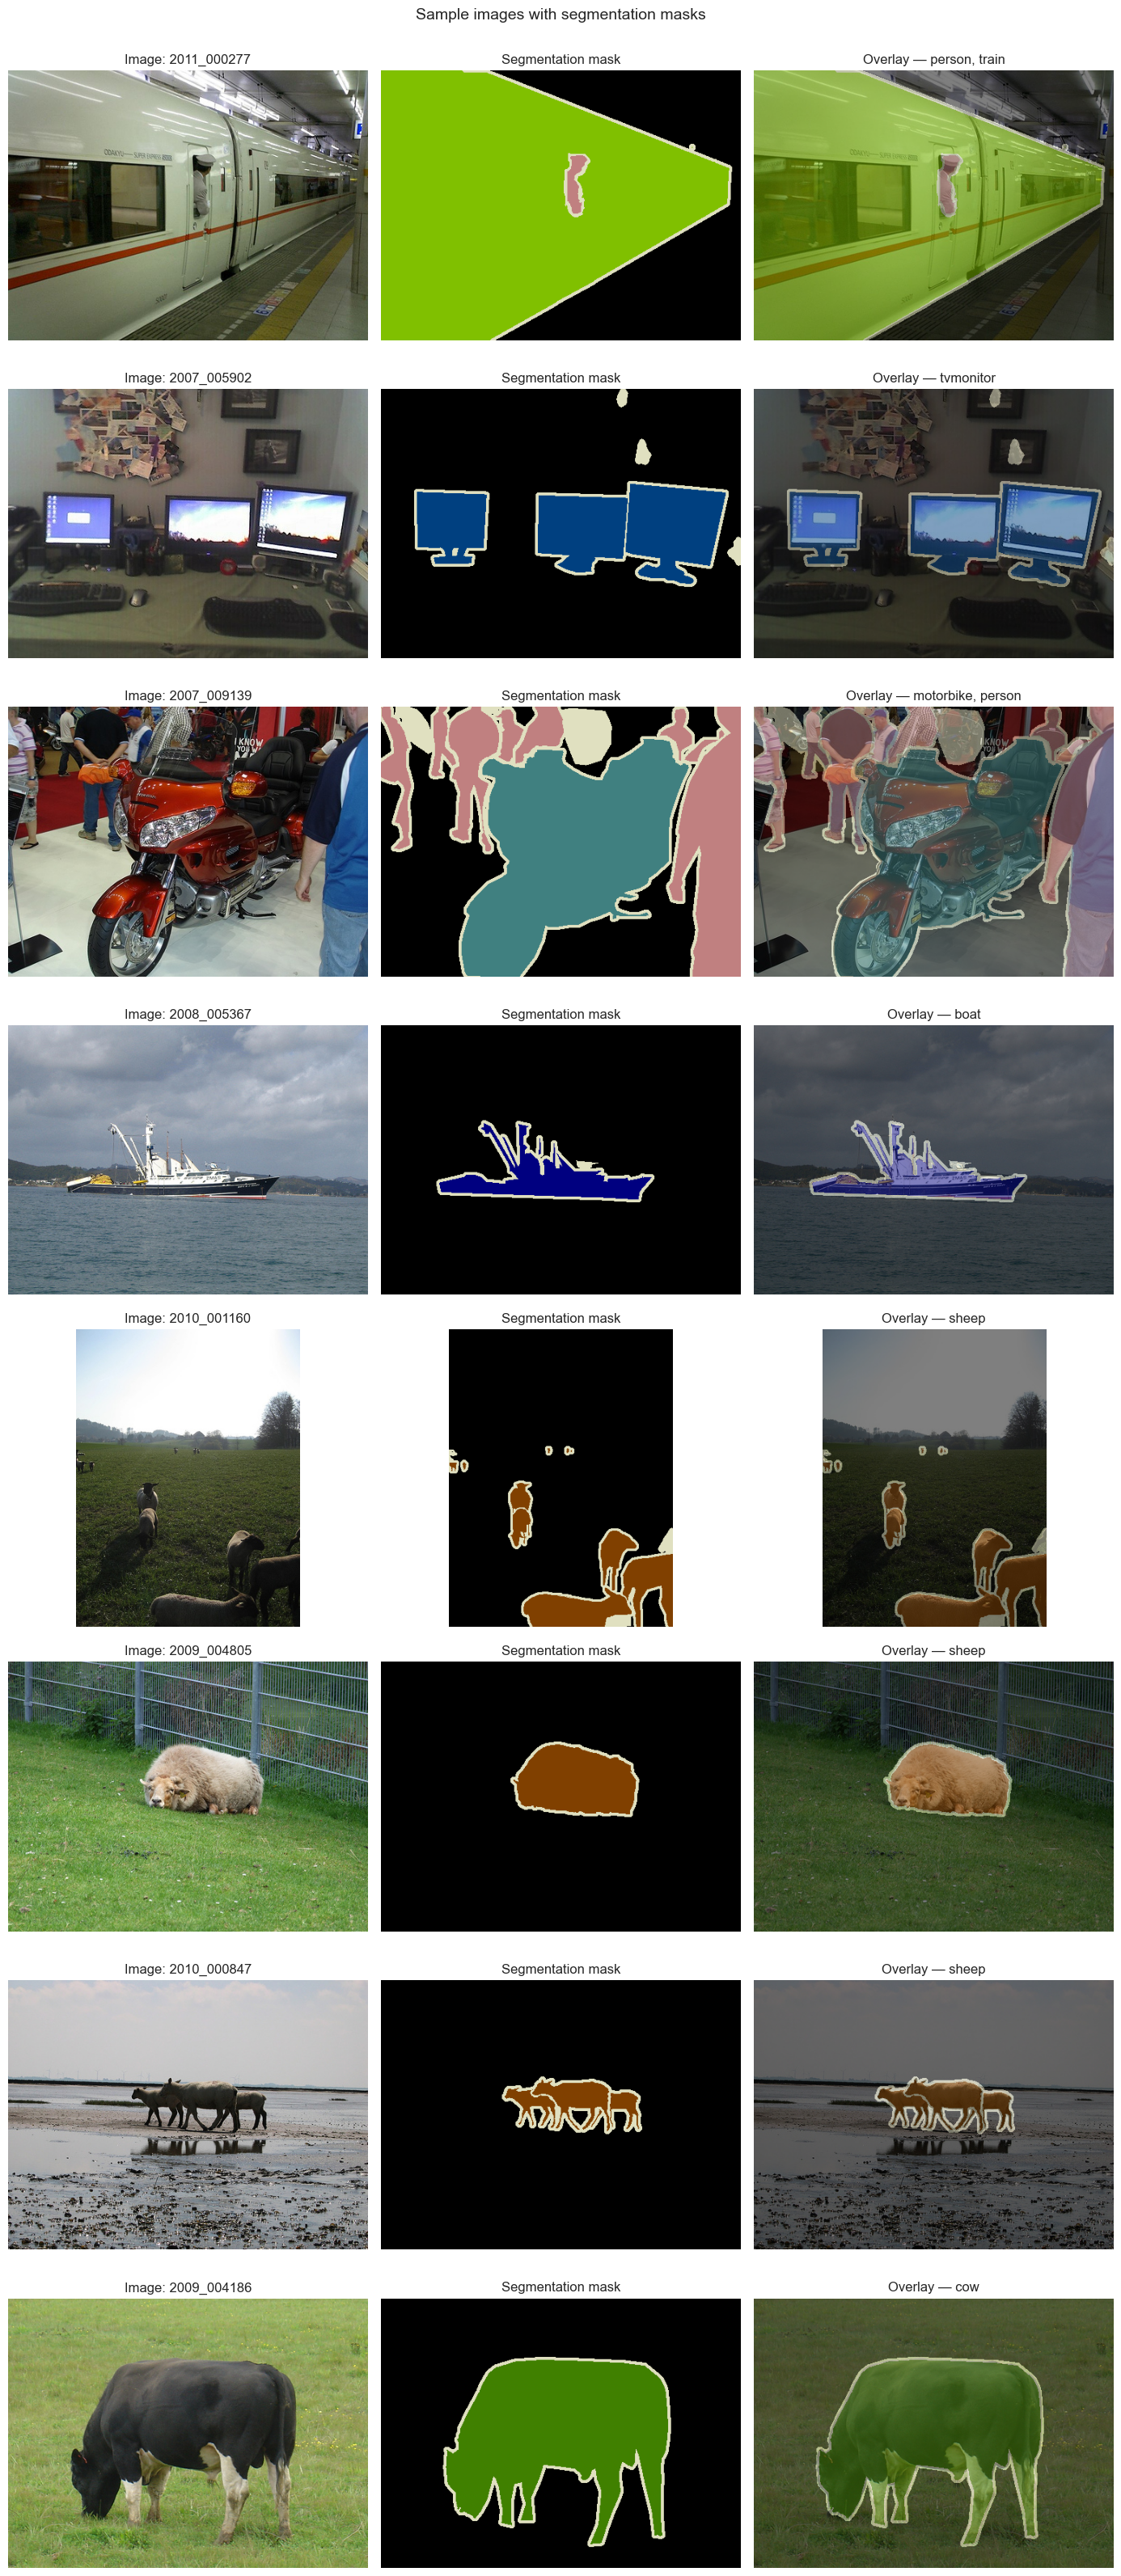

In [8]:
def colorize_mask(mask_np):
    h, w = mask_np.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for c in range(NUM_CLASSES):
        rgb[mask_np == c] = VOC_COLORMAP[c]
    rgb[mask_np == 255] = [224, 224, 192]
    return rgb

np.random.seed(42)
sample_ids = np.random.choice(train_ids, size=8, replace=False)

fig, axes = plt.subplots(8, 3, figsize=(14, 32))
for i, img_id in enumerate(sample_ids):
    img = np.array(Image.open(img_dir / f"{img_id}.jpg"))
    mask = np.array(Image.open(mask_dir / f"{img_id}.png"))
    mask_rgb = colorize_mask(mask)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Image: {img_id}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask_rgb)
    axes[i, 1].set_title("Segmentation mask")
    axes[i, 1].axis("off")

    overlay = (img * 0.5 + mask_rgb * 0.5).astype(np.uint8)
    axes[i, 2].imshow(overlay)
    classes_in_img = sorted(set(np.unique(mask)) - {0, 255})
    class_names = [VOC_CLASSES[c] for c in classes_in_img if c < NUM_CLASSES]
    axes[i, 2].set_title(f"Overlay — {', '.join(class_names)}")
    axes[i, 2].axis("off")

plt.suptitle("Sample images with segmentation masks", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

### 2.5 Foreground-to-background ratio per class

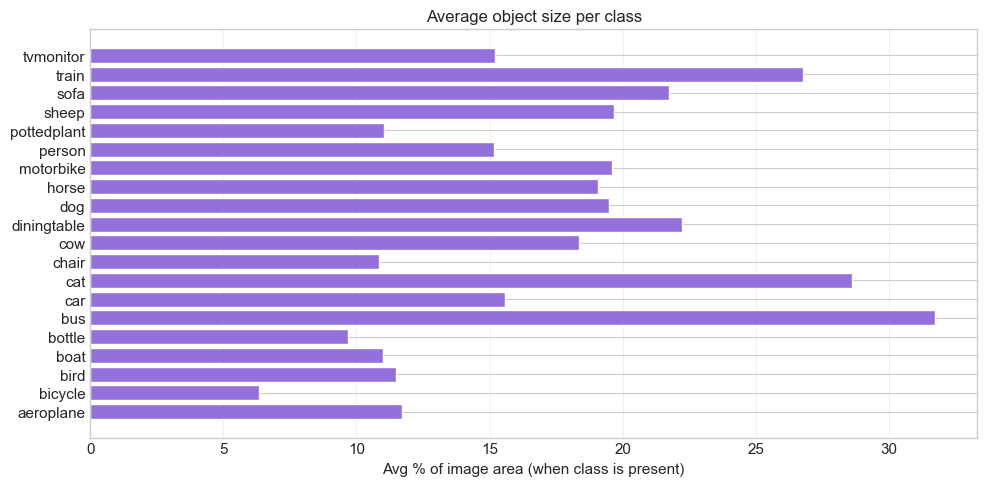

In [9]:
avg_class_area = []
for c in range(1, NUM_CLASSES):
    areas = []
    for img_id in train_ids:
        mask = np.array(Image.open(mask_dir / f"{img_id}.png"))
        total = mask.size
        class_pixels = np.sum(mask == c)
        if class_pixels > 0:
            areas.append(class_pixels / total)
    avg_class_area.append(np.mean(areas) if areas else 0)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(VOC_CLASSES[1:], [a * 100 for a in avg_class_area], color="mediumpurple", edgecolor="white")
ax.set_xlabel("Avg % of image area (when class is present)")
ax.set_title("Average object size per class")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 2.6 Void/border pixel analysis

Pascal VOC uses label 255 for "void" regions (object boundaries and ambiguous areas). These pixels are ignored during evaluation but affect training if not handled.

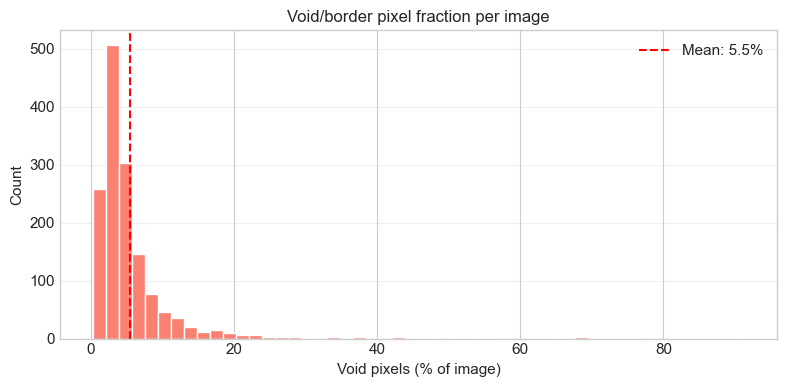

In [10]:
void_fracs = []
for img_id in train_ids:
    mask = np.array(Image.open(mask_dir / f"{img_id}.png"))
    void_fracs.append(np.sum(mask == 255) / mask.size * 100)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(void_fracs, bins=50, color="salmon", edgecolor="white")
ax.set_xlabel("Void pixels (% of image)")
ax.set_ylabel("Count")
ax.set_title("Void/border pixel fraction per image")
ax.axvline(np.mean(void_fracs), color="red", linestyle="--", label=f"Mean: {np.mean(void_fracs):.1f}%")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 2.7 Task and data summary

- **Task:** semantic segmentation — assign one of 21 classes (including background) to every pixel.
- **Train:** 1,464 images, **Val:** 1,449 images. Official split by VOC authors.
- **Classes:** 20 foreground + 1 background. Label 255 = void (ignored in eval).
- **Imbalance:** background dominates (~75% of pixels). Among foreground, **person** is most frequent; small objects (bicycle, bottle) are rare at pixel level.
- **Image sizes:** variable (mostly ~500px on longest side), need resizing/padding for batching.
- **Key insight for modeling:** heavy class imbalance → use class-weighted loss or focal loss; void pixels must be masked during loss computation.

## 3. Metric Analysis

### 3.1 Target metric: mean Intersection over Union (mIoU)

The standard Pascal VOC segmentation metric is **mean IoU (mIoU)**: compute IoU per class, then average across all 21 classes.

$$\text{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}, \quad \text{mIoU} = \frac{1}{C}\sum_{c=1}^{C} \text{IoU}_c$$

**Strengths:**
- Region-overlap metric: directly penalizes both false positives and false negatives.
- Class-averaged: each class contributes equally regardless of pixel frequency → rare classes matter.
- Well-established benchmark: enables direct comparison with published results.

**Weaknesses:**
- Ignores boundary quality — a prediction can have high IoU but jagged boundaries.
- Sensitive to missing rare classes: if a rare class has IoU = 0, it pulls down the mean significantly.
- Does not distinguish between small vs. large errors (a 1-pixel shift penalizes the same as a large miss, proportionally).

**Edge cases:**
- If a class is absent in both GT and prediction → undefined IoU (convention: either skip or count as 1.0). VOC skips classes not present in GT.
- Very small objects can have IoU swinging between 0 and 1 with minor shifts.